# 2장 · 벡터 연산 (덧셈 · 스칼라배 · 내적) ➕✖️

웹 챕터와 짝을 이루는 Python 실습입니다. 벡터를 더하고, 늘이고, 내적을 계산해 봅니다.

준비물: `pip install -r requirements.txt`

> 🤖 **AI 튜터**: 아래 셀을 실행하면 웹앱처럼 화면 오른쪽 아래에 🤖 버튼이 생깁니다.
> 버튼을 누르면 채팅창이 열리고, 어디를 스크롤해도 그 자리에 떠 있어요. 막히면 언제든 질문하세요.
> (로컬 Ollama 필요. 꺼져 있으면 켜는 방법이 안내되고, 튜터 없이도 학습에는 지장 없습니다.)

In [ ]:
# 🤖 AI 튜터 — 실행하면 오른쪽 아래에 🤖 버튼이 떠요 (웹앱과 같은 로컬 AI, 클릭해서 열기)
from tutor import chat

chat('ch2')

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# 한글 폰트 설정 (안 하면 한글 제목/라벨이 네모로 깨짐)
# Windows: 'Malgun Gothic' / macOS: 'AppleGothic' / Linux: 'NanumGothic' 로 바꾸세요
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False  # 음수 부호(-) 깨짐 방지

def setup_plane(ax, r=8):
    ax.set_xlim(-r, r); ax.set_ylim(-r, r)
    ax.axhline(0, color='#94a3b8', lw=1); ax.axvline(0, color='#94a3b8', lw=1)
    ax.grid(True, color='#eef2f7'); ax.set_aspect('equal')

def draw_vec(ax, vec, color, label, tail=(0, 0)):
    ax.quiver(tail[0], tail[1], vec[0], vec[1], angles='xy', scale_units='xy', scale=1,
              color=color, width=0.012)
    tip = (tail[0] + vec[0], tail[1] + vec[1])
    ax.text(tip[0] + 0.2, tip[1] + 0.2, label, color=color)

## 1. 벡터 덧셈: 성분끼리 더하기

NumPy 에서는 그냥 `+` 로 더하면 성분끼리 더해집니다.

In [ ]:
a = np.array([3, 1])
b = np.array([1, 3])
print('a + b =', a + b)   # 성분끼리 더해짐

fig, ax = plt.subplots(figsize=(6, 6))
setup_plane(ax)
draw_vec(ax, a, '#6366f1', 'a')
draw_vec(ax, b, '#ec4899', 'b')
draw_vec(ax, a + b, '#10b981', 'a+b')
draw_vec(ax, b, '#ec4899', '', tail=a)   # 꼬리 잇기 (점선 대신 같은 색)
ax.set_title('벡터 덧셈: 꼬리에 꼬리를 잇기')
plt.show()

## 2. 스칼라배: 늘이기 / 줄이기 / 뒤집기

벡터에 숫자(스칼라)를 곱하면 성분마다 곱해집니다. 음수면 방향이 반대로!

2 x (np.int64(2), np.int64(1)) = (np.int64(4), np.int64(2))
0.5 x (np.int64(2), np.int64(1)) = (np.float64(1.0), np.float64(0.5))
-1 x (np.int64(2), np.int64(1)) = (np.int64(-2), np.int64(-1))


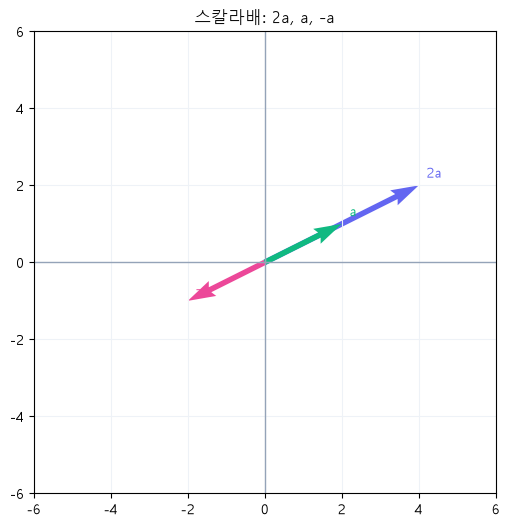

In [8]:
a = np.array([2, 1])
for k in [2, 0.5, -1]:
    print(f'{k} x {tuple(a)} = {tuple(k * a)}')

fig, ax = plt.subplots(figsize=(6, 6))
setup_plane(ax, r=6)
draw_vec(ax, 2 * a, '#6366f1', '2a')
draw_vec(ax, a, '#10b981', 'a')
draw_vec(ax, -1 * a, '#ec4899', '-a')
ax.set_title('스칼라배: 2a, a, -a')
plt.show()

## 3. 내적: 성분끼리 곱해서 더하기

`np.dot(a, b)` 또는 `a @ b` 로 내적을 구합니다. 결과는 **숫자(스칼라)** 입니다.

$$\vec{a}\cdot\vec{b} = a_x b_x + a_y b_y = \lVert\vec{a}\rVert\,\lVert\vec{b}\rVert\cos\theta$$

In [9]:
a = np.array([4, 0])
b = np.array([2, 3])

d = np.dot(a, b)
print('a . b =', d)

# 사이 각도 구하기: cos(theta) = (a.b) / (|a||b|)
cos_t = d / (np.linalg.norm(a) * np.linalg.norm(b))
theta = np.degrees(np.arccos(cos_t))
print(f'사이 각도 = {theta:.1f} 도')

a . b = 8
사이 각도 = 56.3 도


## 3-AI. 코사인 유사도: AI가 '비슷함'을 재는 법 🤖

내적은 추천·검색·신경망의 핵심 계산입니다. 내적을 두 벡터 길이로 나눈 **코사인 유사도**로
"내 취향과 가장 닮은 영화"를 골라봅시다. (값이 1에 가까울수록 비슷)

In [10]:
def cosine_similarity(a, b):
    """내적을 두 벡터의 길이로 나눈 값 = cos(theta). -1 ~ 1, 1에 가까울수록 비슷."""
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

# 내 취향을 (액션 선호, 로맨스 선호) 두 숫자로 표현
me = np.array([5, 1])
movies = {
    '액션물 A': np.array([5, 0]),
    '로맨스물 B': np.array([0, 5]),
    '취향저격 C': np.array([5, 1]),
}

for name, v in movies.items():
    print(f'{name}: 내적={np.dot(me, v):>3.0f},  코사인유사도={cosine_similarity(me, v):.2f}')

best = max(movies, key=lambda n: cosine_similarity(me, movies[n]))
print('\n👉 추천:', best)

액션물 A: 내적= 25,  코사인유사도=0.98
로맨스물 B: 내적=  5,  코사인유사도=0.20
취향저격 C: 내적= 26,  코사인유사도=1.00

👉 추천: 취향저격 C


## 4. 직접 풀어보기 ✏️

`(4, k)` 와 `(2, -1)` 이 수직이 되는 `k` 를 찾아보세요. (수직 ⇔ 내적 0, 정답: 8)

In [11]:
# 내적이 0이 되는 k: 4*2 + k*(-1) = 0  ->  k = 8
k = 8
a = np.array([4, k])
b = np.array([2, -1])
print('내적 =', np.dot(a, b))
assert np.dot(a, b) == 0, '아직 수직이 아니에요!'
print('✅ 수직 확인! (내적이 0)')

내적 = 0
✅ 수직 확인! (내적이 0)


---
다음 챕터: **행렬과 행렬 연산**. 여러 수를 표로 묶어 다룹니다. 🙂